# Low-Level PDE Solvers & Custom Boundary Conditions (`softpotato.solver`)

## 1. Goal

Formulate `DiffusionProblem` directly with custom `DirichletBC` and `NeumannBC` conditions (including time-dependent BCs) and benchmark all four built-in PDE solvers: `"explicit"` (FTCS), `"implicit"` (BTCS), `"crank_nicolson"`, and `"scipy_ivp"`.

## 2. Canonical Fourier Decay: Comparing All Four Solvers

We solve the 1D diffusion equation on $x \in [0, 1]$ with $D = 0.05$:

$$
\frac{\partial c}{\partial t} = D \frac{\partial^2 c}{\partial x^2}, \quad c(0, t) = c(1, t) = 0, \quad c(x, 0) = \sin(\pi x)
$$

whose exact analytical solution is $c_{\text{exact}}(x, t) = \sin(\pi x)\exp(-\pi^2 D t)$. Note that `"explicit"` (FTCS) enforces the CFL stability condition $r = D\,\Delta t / \Delta x^2 \le 0.5$.

In [1]:
# !pip install -q softpotato

import time
import matplotlib.pyplot as plt
import numpy as np

from softpotato.analytical.benchmark import compute_error_metrics
from softpotato.solver import (
    DiffusionProblem,
    DirichletBC,
    NeumannBC,
    get_solver,
    list_solvers,
)

print("Available solvers:", list_solvers())

D = 0.05
x = np.linspace(0.0, 1.0, 51)
dx = x[1] - x[0]
t_end = 0.4
t_eval = np.linspace(0.0, t_end, 21)

problem = DiffusionProblem(
    grid=x,
    diffusivity={"c": D},
    boundary_conditions={"c": (DirichletBC(0.0), DirichletBC(0.0))},
    initial_conditions={"c": lambda x_arr: np.sin(np.pi * x_arr)},
)

c_exact = np.sin(np.pi * x)[None, :] * np.exp(-np.pi**2 * D * t_eval[:, None])

# CFL-safe dt for explicit FTCS: dt <= 0.5 * dx^2 / D
dt_explicit = 0.4 * dx**2 / D
solver_configs = [
    ("explicit", {"dt": dt_explicit}),
    ("implicit", {"dt": 0.005}),
    ("crank_nicolson", {"dt": 0.005}),
    ("scipy_ivp", {"method": "BDF", "rtol": 1e-7, "atol": 1e-9}),
]

results = {}
for name, kwargs in solver_configs:
    t0 = time.perf_counter()
    solver = get_solver(name, **kwargs)
    res = solver.solve(problem, t_span=(0.0, t_end), t_eval=t_eval)
    elapsed = time.perf_counter() - t0
    metrics = compute_error_metrics(res.concentrations["c"], c_exact)
    results[name] = (res, metrics, elapsed)
    print(
        f"{name:<15s} | success={res.success} | L2={metrics.l2_error:.3e} "
        f"| L_inf={metrics.max_abs_error:.3e} | time={elapsed*1e3:.2f} ms"
    )

Available solvers: ['btcs', 'crank-nicolson', 'crank_nicolson', 'explicit', 'ftcs', 'implicit', 'scipy_ivp', 'solve_ivp']
explicit        | success=True | L2=4.109e-05 | L_inf=6.096e-05 | time=8.55 ms
implicit        | success=True | L2=1.590e-04 | L_inf=2.329e-04 | time=4.58 ms
crank_nicolson  | success=True | L2=3.588e-05 | L_inf=5.323e-05 | time=5.19 ms
scipy_ivp       | success=True | L2=3.582e-05 | L_inf=5.324e-05 | time=12.58 ms


## 3. Visualizing Solver Accuracy

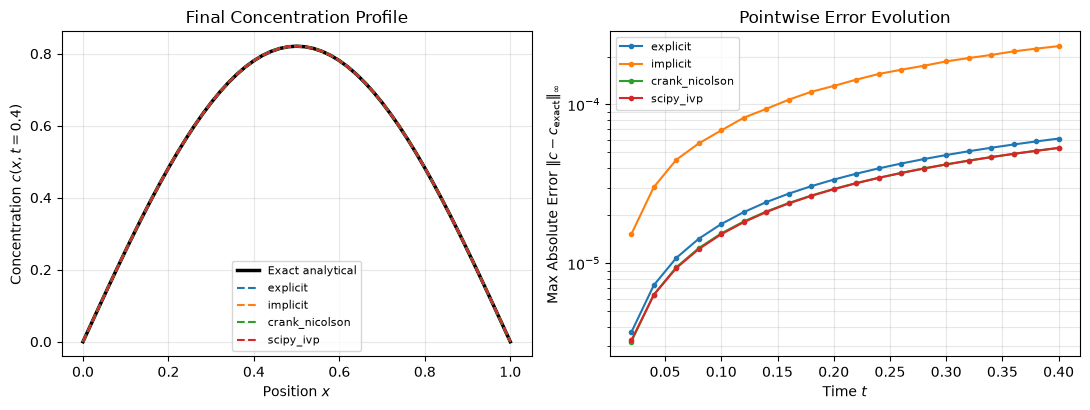

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.plot(x, c_exact[-1], "k-", lw=2.5, label="Exact analytical")
for name, (res, _, _) in results.items():
    ax1.plot(x, res.concentrations["c"][-1], "--", label=name)
ax1.set_xlabel("Position $x$")
ax1.set_ylabel(f"Concentration $c(x, t={t_end})$")
ax1.set_title("Final Concentration Profile")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

for name, (res, _, _) in results.items():
    err_t = np.max(np.abs(res.concentrations["c"] - c_exact), axis=1)
    ax2.semilogy(t_eval[1:], err_t[1:], marker="o", ms=3, label=name)
ax2.set_xlabel("Time $t$")
ax2.set_ylabel(r"Max Absolute Error $\|c - c_{\mathrm{exact}}\|_\infty$")
ax2.set_title("Pointwise Error Evolution")
ax2.legend(fontsize=8)
ax2.grid(True, which="both", alpha=0.3)

fig.tight_layout()
plt.show()

## 4. Custom Time-Dependent Dirichlet & Neumann Boundary Conditions

`DirichletBC(callable)` and `NeumannBC(callable)` accept any function `f(t)` of time. Here we impose a sinusoidal surface concentration at $x = 0$ and a zero-flux insulating wall (`NeumannBC(0.0)`) at $x = L$.

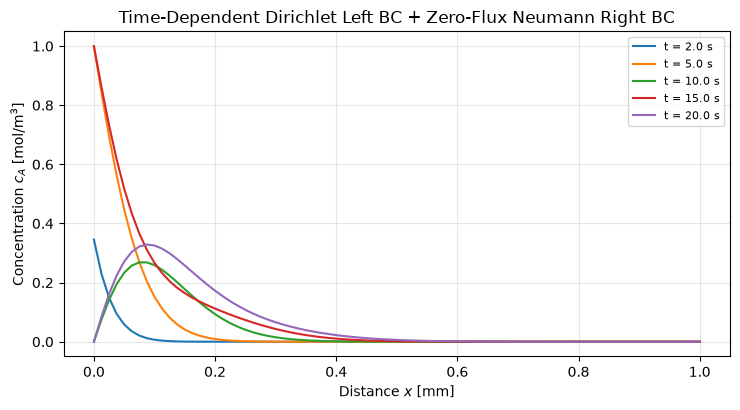

In [3]:
L = 1.0e-3
D_phys = 1.0e-9
x_bc = np.linspace(0.0, L, 81)
t_bc = np.linspace(0.0, 20.0, 101)

# Time-dependent Dirichlet BC at x=0, zero-flux Neumann BC at x=L
prob_td = DiffusionProblem(
    grid=x_bc,
    diffusivity={"A": D_phys},
    boundary_conditions={
        "A": (
            DirichletBC(lambda t: 0.5 * (1.0 - np.cos(2.0 * np.pi * t / 10.0))),
            NeumannBC(0.0),
        )
    },
    initial_conditions={"A": 0.0},
)

res_td = get_solver("crank_nicolson", dt=0.1).solve(
    prob_td, t_span=(0.0, 20.0), t_eval=t_bc
)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for idx in [10, 25, 50, 75, 100]:
    ax.plot(x_bc * 1e3, res_td.concentrations["A"][idx], label=f"t = {t_bc[idx]:.1f} s")
ax.set_xlabel("Distance $x$ [mm]")
ax.set_ylabel(r"Concentration $c_A$ [$\mathrm{mol/m^3}$]")
ax.set_title("Time-Dependent Dirichlet Left BC + Zero-Flux Neumann Right BC")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Key Takeaways

- `DiffusionProblem` decouples the physical PDE (grid, diffusivity, BCs, ICs) from the numerical integrator (`get_solver()`).
- `"crank_nicolson"` and `"scipy_ivp"` achieve 2nd-order or adaptive high accuracy without the restrictive CFL time-step limit of `"explicit"`.
- `DirichletBC(fn)` and `NeumannBC(fn)` support arbitrary time-dependent boundary forcing.